# Laboratory 5 — Titanic Passenger Survival Prediction System
**Course:** Introduction to Artificial Intelligence (AI–101L) · **CLO:** CLO–3

This completed notebook uses the supplied **`sample-data.csv`**. It follows the six ML steps from the original lab, solves Exercises 1–5 and the home assignment, and saves artifacts for Lab 06.

**Objectives:** (1) load and explore a CSV, (2) preprocess categorical features without leakage, (3) stratified train–test split, (4) compare Logistic Regression / Decision Tree / Random Forest, (5) accuracy, confusion matrix, classification report, ROC/AUC, and five-fold CV, (6) tune and persist a reusable pipeline.

**Important dataset limitation:** The uploaded file contains **100 rows**, not the full Kaggle Titanic dataset. Its four predictors are categorical (`PClass`, `Gender`, `Sibling`, `Embarked`). It has neither `SibSp` nor `Parch`, so real `FamilySize` and `IsAlone` cannot be derived; Exercise 1 uses documented sibling-only **proxies**, not genuine family composition. This prevents misleading claims about those features.

## Step 1 — Import libraries
The notebook assumes `numpy`, `pandas`, `scikit-learn`, `matplotlib`, and `joblib` are installed. All paths below are relative to the notebook working directory (`lab05`).

In [1]:
from pathlib import Path
import json
import pickle
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score

RANDOM_STATE = 42
CATEGORICAL = ["PClass", "Gender", "Sibling", "Embarked"]
OUTPUT_DIR = Path(".")
(OUTPUT_DIR / "figures").mkdir(exist_ok=True)
print("Imports successful")

Imports successful


## Step 2 — Load and explore the sample data
Check size, class balance, missing values, and available feature values **before** modeling. A majority-class classifier provides the accuracy baseline.

In [2]:
data = pd.read_csv("sample-data.csv")
expected = CATEGORICAL + ["Survived"]
assert set(expected) == set(data.columns), f"Unexpected columns: {list(data.columns)}"
assert data["Survived"].dropna().isin(["Yes", "No"]).all(), "Unexpected target labels"
print("Rows / columns:", data.shape)
print("\nFirst 5 rows:\n", data.head().to_string(index=False))
print("\nMissing values:\n", data.isna().sum().to_string())
print("\nTarget distribution:\n", data["Survived"].value_counts().to_string())
print("\nCategory levels:")
for column in CATEGORICAL:
    print(column, sorted(data[column].dropna().unique()))
baseline_accuracy = data["Survived"].value_counts(normalize=True).max()
print(f"\nMajority-class baseline = {baseline_accuracy:.1%}")

Rows / columns: (100, 5)

First 5 rows:
 PClass Gender Sibling    Embarked Survived
 Third   Male     One Southampton       No
Second Female    Zero Southampton      Yes
 Third   Male    Zero Southampton       No
 Third Female   Three Southampton      Yes
 Third   Male    Zero  Queenstown       No

Missing values:
 PClass      0
Gender      0
Sibling     0
Embarked    0
Survived    0

Target distribution:
 Survived
No     50
Yes    50

Category levels:
PClass ['First', 'Second', 'Third']
Gender ['Female', 'Male']
Sibling ['One', 'Three', 'Two', 'Zero']
Embarked ['Cherbourg', 'Queenstown', 'Southampton']

Majority-class baseline = 50.0%


## Step 3 — Stratified train–test split (80/20)
The test set is held out until evaluation. We also fit the **target** label encoder on training labels only. The encoder maps `No` → 0 and `Yes` → 1.

In [3]:
X = data[CATEGORICAL].copy()
y_text = data["Survived"].copy()
X_train, X_test, y_train_text, y_test_text = train_test_split(
    X, y_text, test_size=0.20, stratify=y_text, random_state=RANDOM_STATE
)
target_encoder = LabelEncoder().fit(y_train_text)
y_train = target_encoder.transform(y_train_text)
y_test = target_encoder.transform(y_test_text)
assert list(target_encoder.classes_) == ["No", "Yes"]
print("Training size:", len(X_train), "Testing size:", len(X_test))
print("Training labels:", pd.Series(y_train).value_counts().sort_index().to_dict())
print("Testing labels:", pd.Series(y_test).value_counts().sort_index().to_dict())

Training size: 80 Testing size: 20
Training labels: {0: 40, 1: 40}
Testing labels: {0: 10, 1: 10}


## Step 4 — Build preprocessing and models

- **Missing categorical values:** most-frequent imputation.
- **Categorical values:** one-hot encoding (appropriate because classes/ports are nominal).
- **Scaling:** StandardScaler for numeric model inputs (included for a common evaluation protocol, though trees do not need it).
- **No leakage:** the `Pipeline` fits all learned transforms on each training fold, never on the held-out fold or test set.

`Sibling` is deliberately treated as categorical in the base model; the numeric meaning is addressed separately in Exercise 1.

In [4]:
def make_preprocessor(include_family_proxies=False):
    category_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ("scaler", StandardScaler()),
    ])
    transformers = [("categorical", category_pipeline, CATEGORICAL)]
    if include_family_proxies:
        numeric_pipeline = Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ])
        transformers.append(("numeric", numeric_pipeline, ["FamilySize", "IsAlone"]))
    return ColumnTransformer(transformers=transformers, remainder="drop")


def make_pipeline(estimator, include_family_proxies=False):
    return Pipeline(steps=[
        ("preprocessor", make_preprocessor(include_family_proxies)),
        ("model", clone(estimator)),
    ])

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=150, random_state=RANDOM_STATE),
}


def evaluate_models(model_dict, train_features=X_train, test_features=X_test, use_proxies=False):
    rows = []
    for name, estimator in model_dict.items():
        pipeline = make_pipeline(estimator, include_family_proxies=use_proxies)
        pipeline.fit(train_features, y_train)
        predictions = pipeline.predict(test_features)
        rows.append({"Model": name, "Test Accuracy": float(accuracy_score(y_test, predictions))})
    return pd.DataFrame(rows)

print("Pipelines prepared; all learned preprocessing occurs within model fitting.")

Pipelines prepared; all learned preprocessing occurs within model fitting.


## Step 5 — Train and compare the three required classifiers
Use the *same* split, features, preprocessing, and scoring for all models.

In [5]:
three_model_results = evaluate_models(models)
print(three_model_results.to_string(index=False, formatters={"Test Accuracy": "{:.3f}".format}))

              Model Test Accuracy
Logistic Regression         0.500
      Decision Tree         0.550
      Random Forest         0.500


## Exercise 1 — Compare with/without `FamilySize` and `IsAlone`
**Data quality note:** Standard Titanic `FamilySize = SibSp + Parch + 1` and `IsAlone = (FamilySize == 1)` are **not computable** from the supplied file. For a reproducible educational comparison, define **proxies**: `FamilySize = Sibling_count + 1`, `IsAlone = (Sibling_count == 0)`. These are sibling-based estimates and can be wrong if a passenger traveled with parents/children or spouses. We retain the required feature names for the exercise but do not claim they are true family size/alone indicators.

In [6]:
sibling_counts = {"Zero": 0, "One": 1, "Two": 2, "Three": 3}

def add_sibling_proxies(X_raw):
    out = X_raw.copy()
    counts = out["Sibling"].map(sibling_counts)
    if counts.isna().any():
        raise ValueError("Sibling value not supported by the provided CSV's category mapping")
    out["FamilySize"] = counts + 1
    out["IsAlone"] = (counts == 0).astype(int)
    return out

X_train_with = add_sibling_proxies(X_train)
X_test_with = add_sibling_proxies(X_test)
with_proxy_results = evaluate_models(models, X_train_with, X_test_with, use_proxies=True)
exercise1 = three_model_results.merge(with_proxy_results, on="Model", suffixes=(" Without", " With"))
exercise1["Accuracy Delta"] = exercise1["Test Accuracy With"] - exercise1["Test Accuracy Without"]
print(exercise1.to_string(index=False, formatters={k:"{:+.3f}".format if k=="Accuracy Delta" else "{:.3f}".format for k in exercise1.columns if "Accuracy" in k or "Delta" in k}))
print("Note: accuracy deltas come from only 20 test records; they are noisy.")

              Model Test Accuracy Without Test Accuracy With Accuracy Delta
Logistic Regression                 0.500              0.500         +0.000
      Decision Tree                 0.550              0.550         +0.000
      Random Forest                 0.500              0.500         +0.000
Note: accuracy deltas come from only 20 test records; they are noisy.


## Exercise 3 — Five-fold cross-validation stability
Apply stratified five-fold CV to **training data**, so the test set is not part of CV. Report mean and standard deviation of fold accuracy.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def compare_cv(model_dict):
    rows=[]
    for name, estimator in model_dict.items():
        scores = cross_val_score(make_pipeline(estimator), X_train, y_train, scoring="accuracy", cv=cv, n_jobs=1)
        rows.append({"Model":name, "CV Mean":float(scores.mean()), "CV Std":float(scores.std()), "Fold Scores":scores.tolist()})
    return pd.DataFrame(rows)

cv_three = compare_cv(models)
print(cv_three[["Model", "CV Mean", "CV Std"]].to_string(index=False, formatters={"CV Mean":"{:.3f}".format, "CV Std":"{:.3f}".format}))

              Model CV Mean CV Std
Logistic Regression   0.688  0.153
      Decision Tree   0.688  0.119
      Random Forest   0.675  0.145


## Exercise 4 — Add KNN and SVC; re-run unchanged comparison
Only the model dictionary changes; the `evaluate_models` and `compare_cv` functions stay the same.

In [8]:
models.update({
    "KNeighborsClassifier": KNeighborsClassifier(n_neighbors=5),
    "SVC": SVC(C=1.0, kernel="rbf"),
})
five_model_results = evaluate_models(models)
cv_five = compare_cv(models)
all_model_results = five_model_results.merge(cv_five, on="Model")
print(all_model_results[["Model", "Test Accuracy", "CV Mean", "CV Std"]].to_string(
    index=False, formatters={"Test Accuracy":"{:.3f}".format, "CV Mean":"{:.3f}".format, "CV Std":"{:.3f}".format}))

               Model Test Accuracy CV Mean CV Std
 Logistic Regression         0.500   0.688  0.153
       Decision Tree         0.550   0.688  0.119
       Random Forest         0.500   0.675  0.145
KNeighborsClassifier         0.600   0.650  0.094
                 SVC         0.550   0.675  0.145


## Step 6 — Hyperparameter tuning (`GridSearchCV`)
For each model, select hyperparameters by **training-fold cross-validation only**. Select the deployment candidate with the highest mean CV score; if tied, break ties alphabetically to ensure reproducibility. Only then inspect its single untouched test evaluation.

In [9]:
parameter_grids = {
    "Logistic Regression": {"model__C": [0.1, 1, 10]},
    "Decision Tree": {"model__max_depth": [2, 4, None], "model__min_samples_leaf": [1, 3]},
    "Random Forest": {"model__n_estimators": [50, 100], "model__max_depth": [3, None], "model__min_samples_leaf": [1, 3]},
    "KNeighborsClassifier": {"model__n_neighbors": [3, 5, 7], "model__weights": ["uniform", "distance"]},
    "SVC": {"model__C": [0.1, 1, 10], "model__kernel": ["linear", "rbf"]},
}
searches = {}
tuning_rows = []
for name, estimator in models.items():
    search = GridSearchCV(make_pipeline(estimator), parameter_grids[name], scoring="accuracy", cv=cv, n_jobs=1, refit=True)
    search.fit(X_train, y_train)
    searches[name] = search
    tuning_rows.append({"Model": name, "Tuned CV Mean": float(search.best_score_), "Best Parameters": search.best_params_})
tuned_summary = pd.DataFrame(tuning_rows).sort_values(["Tuned CV Mean", "Model"], ascending=[False, True]).reset_index(drop=True)
winning_name = tuned_summary.loc[0, "Model"]
best_search = searches[winning_name]
best_pipeline = best_search.best_estimator_
print(tuned_summary.to_string(index=False, formatters={"Tuned CV Mean":"{:.3f}".format}))
print("\nChosen from CV scores:", winning_name, "| Tuned CV:", round(best_search.best_score_, 3))

               Model Tuned CV Mean                                                                  Best Parameters
                 SVC         0.750                                     {'model__C': 0.1, 'model__kernel': 'linear'}
 Logistic Regression         0.725                                                                {'model__C': 0.1}
       Decision Tree         0.713                            {'model__max_depth': 2, 'model__min_samples_leaf': 1}
       Random Forest         0.713 {'model__max_depth': 3, 'model__min_samples_leaf': 1, 'model__n_estimators': 50}
KNeighborsClassifier         0.675                          {'model__n_neighbors': 5, 'model__weights': 'distance'}

Chosen from CV scores: SVC | Tuned CV: 0.75


## Exercise 2 — ROC curve, AUC, and held-out model evaluation
The final model is selected **without using test labels**. Compute its accuracy, confusion matrix, report and ROC/AUC on the untouched 20-person test set. For ROC, use scores from `predict_proba` (or `decision_function` if the classifier lacks probabilities).

Winning model: SVC
Hold-out accuracy: 0.650 | ROC AUC: 0.615
Confusion matrix [rows actual, cols predicted; 0=No, 1=Yes]:
 [[8 2]
 [5 5]]

Classification report:
               precision    recall  f1-score   support

          No       0.62      0.80      0.70        10
         Yes       0.71      0.50      0.59        10

    accuracy                           0.65        20
   macro avg       0.66      0.65      0.64        20
weighted avg       0.66      0.65      0.64        20



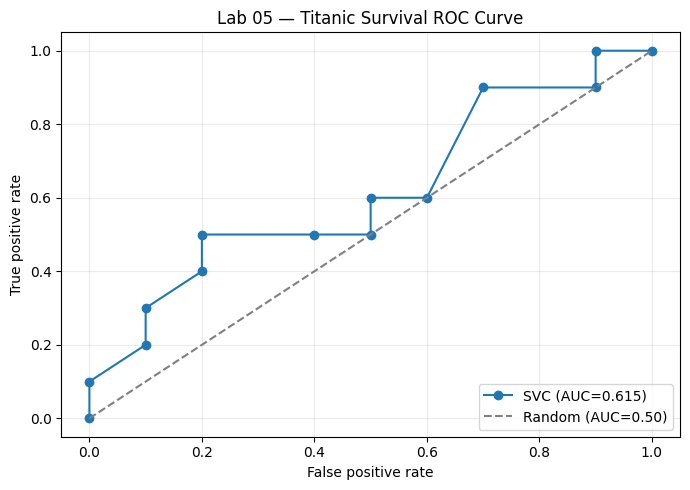

In [10]:
test_predictions = best_pipeline.predict(X_test)
test_accuracy = float(accuracy_score(y_test, test_predictions))
if hasattr(best_pipeline, "predict_proba"):
    positive_scores = best_pipeline.predict_proba(X_test)[:, 1]
else:
    positive_scores = best_pipeline.decision_function(X_test)
fpr, tpr, thresholds = roc_curve(y_test, positive_scores)
auc = float(roc_auc_score(y_test, positive_scores))
cm = confusion_matrix(y_test, test_predictions)
report_text = classification_report(y_test, test_predictions, target_names=list(target_encoder.classes_), zero_division=0)
print("Winning model:", winning_name)
print(f"Hold-out accuracy: {test_accuracy:.3f} | ROC AUC: {auc:.3f}")
print("Confusion matrix [rows actual, cols predicted; 0=No, 1=Yes]:\n", cm)
print("\nClassification report:\n", report_text)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, marker="o", label=f"{winning_name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random (AUC=0.50)")
plt.title("Lab 05 — Titanic Survival ROC Curve")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("figures/roc_curve.png", dpi=160)
plt.show()

## Home Assignment — Pipeline vs manual preprocessing for five-fold CV
The pipeline version fits **imputation, one-hot encoding and scaling inside each fold**. To illustrate the common manual mistake, we first fit preprocessing once on the *entire training partition* and only then cross-validate the estimator. This manual CV allows the validation folds to influence preprocessing statistics, so the manual CV estimate has potential leakage. The separate held-out 20% test set is **not** involved in either CV.

The difference can be **zero** on this toy dataset, because all predictor categories may be present in every fold and missingness is absent; leaking information does not guarantee a better score.

In [11]:
manual_preprocessor = make_preprocessor()
X_train_preprocessed_once = manual_preprocessor.fit_transform(X_train)
manual_scores = cross_val_score(clone(best_pipeline.named_steps["model"]), X_train_preprocessed_once, y_train, cv=cv, scoring="accuracy", n_jobs=1)
pipeline_scores = cross_val_score(clone(best_pipeline), X_train, y_train, cv=cv, scoring="accuracy", n_jobs=1)
cv_comparison = pd.DataFrame({"Manual preprocessed CV": manual_scores, "Fold-safe pipeline CV": pipeline_scores})
print(cv_comparison.to_string(index=False))
print(f"Manual CV mean: {manual_scores.mean():.3f}")
print(f"Pipeline CV mean: {pipeline_scores.mean():.3f}")
print(f"Pipeline minus manual: {(pipeline_scores.mean()-manual_scores.mean()):+.3f}")
print("For formal selection, prefer the GridSearchCV training-fold score above; manual CV is illustrative only.")

 Manual preprocessed CV  Fold-safe pipeline CV
                  0.875                  0.875
                  0.625                  0.625
                  0.625                  0.625
                  0.875                  0.875
                  0.750                  0.750
Manual CV mean: 0.750
Pipeline CV mean: 0.750
Pipeline minus manual: +0.000
For formal selection, prefer the GridSearchCV training-fold score above; manual CV is illustrative only.


## Application phase — Predict an unseen passenger
**Do not label encode the input yourself** before calling the saved model: the fitted pipeline handles preprocessing automatically.

In [12]:
new_passenger = pd.DataFrame([{
    "PClass":"First", "Gender":"Female", "Sibling":"Zero", "Embarked":"Southampton"
}])
predicted_code = best_pipeline.predict(new_passenger)
predicted_label = target_encoder.inverse_transform(predicted_code)[0]
print("New passenger:\n", new_passenger.to_string(index=False))
print("Predicted survival:", predicted_label)

New passenger:
 PClass Gender Sibling    Embarked
 First Female    Zero Southampton
Predicted survival: Yes


## Persist the winning estimator, label encoders and metrics
`joblib` saves the **complete fitted pipeline** (including the fitted `OneHotEncoder` and scaler). The legacy `.pkl` encoders are also saved because the lab explicitly lists them as deliverables; they are **reference/compatibility files** and must not be applied to input before using the pipeline, or features would be transformed twice. For a separate FastAPI process, load the `.joblib` file using `joblib.load` in a trusted environment.

In [13]:
joblib.dump(best_pipeline, "titanic_best_model.joblib")
for column, filename in [
    ("PClass", "pclass_encoder.pkl"),
    ("Gender", "gender_encoder.pkl"),
    ("Sibling", "sibling_encoder.pkl"),
    ("Embarked", "embarked_encoder.pkl"),
]:
    encoder = LabelEncoder().fit(X_train[column].dropna().astype(str))
    with open(filename, "wb") as file:
        pickle.dump(encoder, file)
with open("survived_encoder.pkl", "wb") as file:
    pickle.dump(target_encoder, file)

# Verify that the saved pipeline is usable from disk.
loaded_pipeline = joblib.load("titanic_best_model.joblib")
assert np.array_equal(loaded_pipeline.predict(X_test), test_predictions)
metrics = {
    "dataset_rows": int(len(data)),
    "training_rows": int(len(X_train)),
    "testing_rows": int(len(X_test)),
    "majority_baseline": float(baseline_accuracy),
    "target_balance": {str(k): int(v) for k, v in data["Survived"].value_counts().items()},
    "three_models": three_model_results.to_dict(orient="records"),
    "five_models": all_model_results[["Model","Test Accuracy","CV Mean","CV Std"]].to_dict(orient="records"),
    "family_proxy_comparison": exercise1.to_dict(orient="records"),
    "tuning": tuned_summary.to_dict(orient="records"),
    "winner": winning_name,
    "winner_parameters": best_search.best_params_,
    "winner_cv": float(best_search.best_score_),
    "winner_test_accuracy": test_accuracy,
    "roc_auc": auc,
    "confusion_matrix": cm.tolist(),
    "classification_report": report_text,
    "manual_cv_mean": float(manual_scores.mean()),
    "pipeline_cv_mean": float(pipeline_scores.mean()),
    "demo_prediction": predicted_label,
}
with open("results.json", "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2)
print("Saved titanic_best_model.joblib, 5 encoder .pkl files, figures/roc_curve.png, results.json")

Saved titanic_best_model.joblib, 5 encoder .pkl files, figures/roc_curve.png, results.json


## Exercise 5 — Discussion and deployment decision
A detailed report is provided in **`report.md`**, including: EDA, three-model and five-model comparisons, feature engineering deltas, fold stability, tuning winner, ROC/AUC, leakage comparison, and recommendations.

**Feedback phase:** Record model input, predicted outcome and user feedback for future analysis, subject to privacy and permission. **Improvement phase:** obtain a larger representative dataset with `Age`, `Fare`, `SibSp` and `Parch`, rerun reproducible evaluation, and monitor real-world performance. Because this is a 100-row teaching CSV, treat the resulting model as a classroom demo, **not** a real maritime safety tool.